# Blick: pipeline de segmentação e classificação de plantas de milho

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blick-ai/blick-treino/blob/main/notebooks/pipeline_milho_executavel.ipynb)

Este notebook roda **sem Google Drive**: ele baixa o repositório (pesos e fotos de exemplo) e executa o pipeline completo.

**Como usar:** abra no Colab e clique em *Ambiente de execução > Executar tudo*. Funciona em CPU; com GPU (T4) fica mais rápido.

**Pipeline (duas redes neurais convolucionais, família YOLO26):**
1. **Segmentação de instâncias** (`yolo26n-seg`): acha cada planta de milho e devolve um polígono.
2. **Isolamento**: recorta cada planta e pinta de preto o que está fora do polígono.
3. **Classificação** (`yolo26n-cls`): classifica cada recorte como `healthy` ou `unhealthy`.

**Regra por imagem:** basta uma planta `unhealthy` para a foto inteira ser `unhealthy`.

**Treino ao vivo:** a seção 2 mostra como uma rede neural aprende (passada direta, loss, retropropagação e atualização dos pesos), primeiro numa rede pequena escrita à mão e depois com o YOLO26 treinando no dataset real do Blick (poucas épocas).

**Ordem do notebook:** treino (seções 2 a 4) e depois inferência (seções 5 a 9).

## 1. Instalação e download do repositório

In [1]:
!pip install -q ultralytics

import os
REPO_URL = "https://github.com/blick-ai/blick-treino.git"
if os.path.basename(os.getcwd()) != "blick-treino":
    if not os.path.exists("blick-treino"):
        !git clone -q {REPO_URL}
    %cd blick-treino
!git pull -q          # garante a versão mais recente do repositório (pesos, fotos e resultados salvos)
!ls

/content/blick-treino
images_test  README.md	       resultados		weights
notebooks    requirements.txt  runs_demo_resultado.zip


### Imports e dispositivo

As bibliotecas e o dispositivo (GPU ou CPU) ficam aqui, porque o treino (seções 2 a 4) vem antes da inferência (seções 5 a 9).

In [2]:
import torch, cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Dispositivo:", "GPU" if DEVICE == 0 else "CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dispositivo: GPU


## 2. Como a rede aprende: treino ao vivo

Antes de usar as redes que já estavam treinadas (inferência, a partir da seção 5), esta seção mostra o treino de verdade, em duas etapas rápidas:

**2.1 Uma rede neural escrita à mão (PyTorch).** Cada passo do ciclo de aprendizado aparece no código: passada direta, cálculo do erro (loss), retropropagação e atualização dos pesos. Dá para ver a loss caindo e os pesos mudando.

**2.2 O mesmo treino com o YOLO26 (`yolo26n-cls`).** É o treino do classificador do TCC com o **dataset real** (25.220 recortes de milho) e os **mesmos hiperparâmetros** do treino final (`yolo26n-cls`, 224x224, batch 64). A única diferença é o número de épocas: 3 em vez de até 100, para caber na aula. Por isso os resultados desta demonstração **não** são os do modelo final (que está em `weights/classificacao_best.pt`).

**Salvando o resultado:** depois do primeiro treino, o notebook baixa `resultado_treino_demo.zip`. Extraia na raiz do repositório (ele cria `weights/demo_treino_cls.pt` e `resultados/demo_treino_ao_vivo/`) e faça commit. A partir daí o treino é pulado: se o arquivo existe em `weights/`, o notebook carrega; se não existe, treina. Para treinar ao vivo na apresentação, mude `REFAZER_TREINO_DEMO` para `True`.

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 498kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.4MB/s]


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Parâmetros (pesos e vieses): 101770
época 1: loss treino 0.4382 | loss validação 0.2607 | acurácia validação 92.5%
época 2: loss treino 0.2264 | loss validação 0.1803 | acurácia validação 94.8%
época 3: loss treino 0.1698 | loss validação 0.1514 | acurácia validação 95.5%
época 4: loss treino 0.1349 | loss validação 0.1261 | acurácia validação 96.3%
época 5: loss treino 0.1126 | loss validação 0.1066 | acurácia validação 96.8%

Pesos de um neurônio, antes do treino: [    -0.0172      0.0064     -0.0186      0.0082       0.007]
Os mesmos pesos, depois do treino:     [    -0.0362     -0.0062      0.0079      0.0583      0.0355]


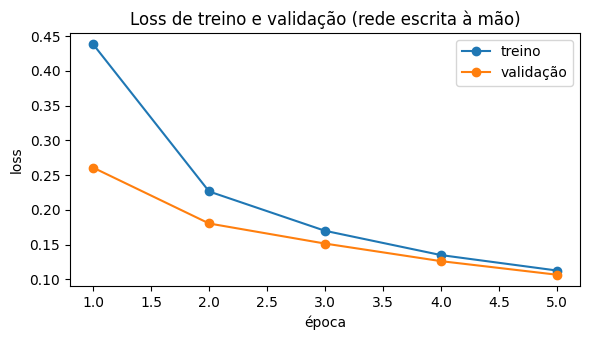

In [3]:
# 2.1 Uma rede neural do zero, para ver o ciclo de aprendizado por dentro
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)

# Dados: dígitos escritos à mão (28x28 pixels), 10 classes. Cada imagem vem com o rótulo certo (aprendizado supervisionado).
tf = transforms.ToTensor()
treino = DataLoader(datasets.MNIST("data_mnist", train=True, download=True, transform=tf), batch_size=64, shuffle=True)
valid = DataLoader(datasets.MNIST("data_mnist", train=False, download=True, transform=tf), batch_size=512)

# A rede: 784 pixels -> 128 neurônios com ativação ReLU -> 10 saídas (uma por dígito)
rede = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)).to(dev)
print(rede)
print("Parâmetros (pesos e vieses):", sum(p.numel() for p in rede.parameters()))

perda_fn = nn.CrossEntropyLoss()                          # mede o erro da previsão
otimizador = torch.optim.SGD(rede.parameters(), lr=0.1)   # ajusta os pesos na direção que reduz o erro

pesos_antes = rede[1].weight[0, 300:305].detach().cpu().clone()
EPOCAS_REDE = 5
hist = {"treino": [], "validacao": []}
for epoca in range(1, EPOCAS_REDE + 1):
    rede.train()
    soma, n = 0.0, 0
    for x, y in treino:
        x, y = x.to(dev), y.to(dev)
        previsao = rede(x)                # 1. passada direta: a imagem atravessa a rede
        perda = perda_fn(previsao, y)     # 2. erro (loss): previsão contra o rótulo certo
        otimizador.zero_grad()
        perda.backward()                  # 3. retropropagação: quanto cada peso contribuiu para o erro
        otimizador.step()                 # 4. atualização: cada peso é ajustado um pouco
        soma += perda.item() * len(x)
        n += len(x)

    rede.eval()
    sv, nv, acertos = 0.0, 0, 0
    with torch.no_grad():                 # validação: só mede, NÃO ajusta nenhum peso
        for x, y in valid:
            x, y = x.to(dev), y.to(dev)
            saida = rede(x)
            sv += perda_fn(saida, y).item() * len(x)
            nv += len(x)
            acertos += (saida.argmax(1) == y).sum().item()
    hist["treino"].append(soma / n)
    hist["validacao"].append(sv / nv)
    print(f"época {epoca}: loss treino {soma/n:.4f} | loss validação {sv/nv:.4f} | acurácia validação {acertos/nv:.1%}")

print("\nPesos de um neurônio, antes do treino:", pesos_antes.numpy().round(4))
print("Os mesmos pesos, depois do treino:    ", rede[1].weight[0, 300:305].detach().cpu().numpy().round(4))

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, EPOCAS_REDE + 1), hist["treino"], marker="o", label="treino")
plt.plot(range(1, EPOCAS_REDE + 1), hist["validacao"], marker="o", label="validação")
plt.xlabel("época"); plt.ylabel("loss"); plt.title("Loss de treino e validação (rede escrita à mão)")
plt.legend(); plt.tight_layout(); plt.show()

In [4]:
# 2.2 Treino real com o YOLO26 (classificador) no dataset do Blick
# Lógica: se já existe um treino demonstrativo salvo em weights/, carrega sem treinar.
# Se não existe (ou se a pasta nem existe), baixa o dataset e treina.
# Depois do treino, a célula seguinte baixa um zip com o resultado: extraia na raiz do repositório e faça commit.
import shutil, zipfile, urllib.request

EPOCAS_DEMO = 3                                  # o treino final usou até 100 épocas (parou na 72 por early stopping)
REFAZER_TREINO_DEMO = False                      # True: ignora o resultado salvo e treina de novo
PESO_DEMO = "weights/demo_treino_cls.pt"         # resultado salvo do treino demonstrativo
PASTA_RES = "resultados/demo_treino_ao_vivo"     # curvas e csv do mesmo treino

TAG_DATASET = "dataset-v1"           # tag do Release do GitHub onde estão os zips
URL_ZIP = f"https://github.com/blick-ai/blick-treino/releases/download/{TAG_DATASET}/blick-classification.zip"
PASTA_DADOS = "dataset/classificacao"

def acha_raiz(pasta):
    # devolve a pasta que contém train/ e valid/ (ou val/), mesmo que o zip tenha uma pasta de embrulho
    for raiz, dirs, _ in os.walk(pasta):
        if "train" in dirs and ({"valid", "val", "validation"} & set(dirs)):
            return raiz
    return None

if os.path.exists(PESO_DEMO) and not REFAZER_TREINO_DEMO:
    print("Treino demonstrativo já salvo. Carregando SEM treinar de novo:", PESO_DEMO)
    demo = YOLO(PESO_DEMO)
    treinou_agora = False
else:
    print("Treino demonstrativo não encontrado em:", os.path.abspath(PESO_DEMO))
    print("Treinando agora...")
    treinou_agora = True
    dados, tam, batch = None, 224, 64
    if not os.path.isdir(PASTA_DADOS):
        try:
            print("Baixando o dataset de classificação (Release do GitHub)...")
            os.makedirs(PASTA_DADOS, exist_ok=True)
            urllib.request.urlretrieve(URL_ZIP, "dataset_cls.zip")
            with zipfile.ZipFile("dataset_cls.zip") as z:
                z.extractall(PASTA_DADOS)
            os.remove("dataset_cls.zip")
        except Exception as e:
            print("Não consegui baixar o dataset:", e)
            shutil.rmtree(PASTA_DADOS, ignore_errors=True)
    dados = acha_raiz(PASTA_DADOS) if os.path.isdir(PASTA_DADOS) else None
    if dados:
        for split in ("train", "valid", "test"):
            for cl in ("healthy", "unhealthy"):
                p = os.path.join(dados, split, cl)
                if os.path.isdir(p):
                    print(f"  {split}/{cl}: {len(os.listdir(p))} imagens")
        print("Dados: dataset real do Blick em", dados)
    else:
        dados, tam, batch = "mnist160", 64, 32
        print("Dataset do Blick indisponível. Usando 'mnist160' (dígitos) só para mostrar o treino.")

    demo = YOLO("yolo26n-cls.pt")    # pesos pré-treinados: transfer learning, não começa do zero
    demo.train(
        data=dados,
        epochs=EPOCAS_DEMO,          # quantas vezes a rede vê o dataset inteiro
        imgsz=tam,                   # tamanho da imagem de entrada
        batch=batch,                 # imagens por atualização de pesos
        patience=20,                 # parada antecipada se a validação parar de melhorar
        project="runs_demo",
        name="demo_treino_ao_vivo",
        device=DEVICE,
        exist_ok=True,
    )
    pasta_run = str(demo.trainer.save_dir)           # pasta onde o Ultralytics realmente salvou
    os.makedirs("weights", exist_ok=True)
    os.makedirs(PASTA_RES, exist_ok=True)
    shutil.copy(f"{pasta_run}/weights/best.pt", PESO_DEMO)
    for f in ("results.png", "results.csv"):
        if os.path.exists(f"{pasta_run}/{f}"):
            shutil.copy(f"{pasta_run}/{f}", f"{PASTA_RES}/{f}")
    print("Treino concluído. Pesos salvos em", PESO_DEMO)

Treino demonstrativo não encontrado em: /content/blick-treino/weights/demo_treino_cls.pt
Treinando agora...
Baixando o dataset de classificação (Release do GitHub)...
  train/healthy: 15905 imagens
  train/unhealthy: 1744 imagens
  valid/healthy: 4533 imagens
  valid/unhealthy: 521 imagens
  test/healthy: 2267 imagens
  test/unhealthy: 250 imagens
Dados: dataset real do Blick em dataset/classificacao
Ultralytics 8.4.209 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/classificacao, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=

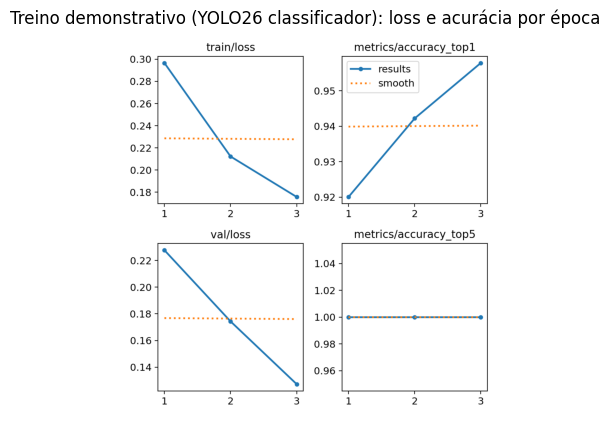

In [5]:
# Curvas do treino demonstrativo: loss e acurácia a cada época
arquivo = f"{PASTA_RES}/results.png"
if os.path.exists(arquivo):
    plt.figure(figsize=(12, 5))
    plt.imshow(mpimg.imread(arquivo)); plt.axis("off")
    plt.title("Treino demonstrativo (YOLO26 classificador): loss e acurácia por época")
    plt.show()
else:
    print("Sem curvas para mostrar:", arquivo)

In [6]:
# Guarda o resultado do treino demonstrativo (só quando o treino acabou de rodar).
# O zip tem os pesos (weights/demo_treino_cls.pt) e as curvas (resultados/demo_treino_ao_vivo/), já com os caminhos certos:
# extraia na raiz do repositório e faça commit. Assim ninguém precisa treinar de novo.
if treinou_agora and os.path.exists(PESO_DEMO):
    with zipfile.ZipFile("resultado_treino_demo.zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(PESO_DEMO, PESO_DEMO)
        for f in ("results.png", "results.csv"):
            origem = f"{PASTA_RES}/{f}"
            if os.path.exists(origem):
                z.write(origem, origem)
    print("Criado resultado_treino_demo.zip")
    try:
        from google.colab import files
        files.download("resultado_treino_demo.zip")
    except Exception as e:
        print("Download automático indisponível aqui:", e)
else:
    print("Nada a salvar: o treino demonstrativo já estava salvo em", PESO_DEMO)

Criado resultado_treino_demo.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3. Resultados do treinamento

Curvas de loss (treino contra validação) e matrizes de confusão no conjunto de teste, dos dois modelos. A ordem é a mesma da seção 2: primeiro o **classificador** (o mesmo modelo que foi treinado ao vivo em 2.2, aqui com o treino completo), depois o **segmentador**.

As matrizes de confusão e as métricas do artigo foram medidas com o recorte original e o corte 0,50 (top-1). A inferência da seção 8 usa recorte quadrado e corte 0,30, então os resultados dela podem diferir destes.

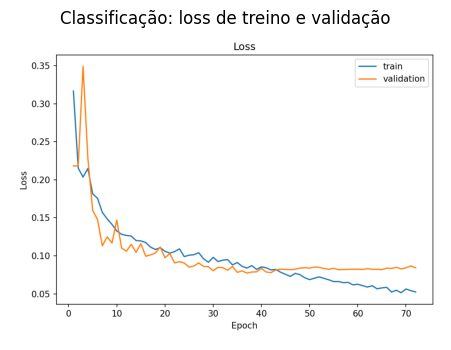

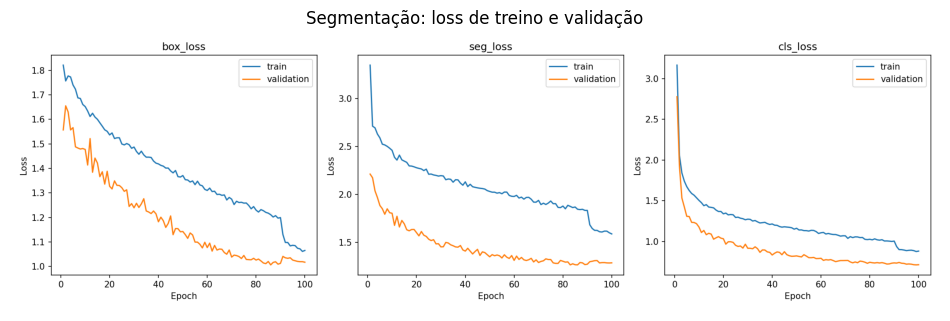

In [7]:
import matplotlib.image as mpimg

for titulo, caminho in [
    ("Classificação: loss de treino e validação", "resultados/classificacao/loss_treino_validacao.png"),
    ("Segmentação: loss de treino e validação", "resultados/segmentacao/loss_treino_validacao_seg.png"),
]:
    if os.path.exists(caminho):
        plt.figure(figsize=(12, 4))
        plt.imshow(mpimg.imread(caminho)); plt.axis("off"); plt.title(titulo)
        plt.show()
    else:
        print("Arquivo não encontrado:", caminho)

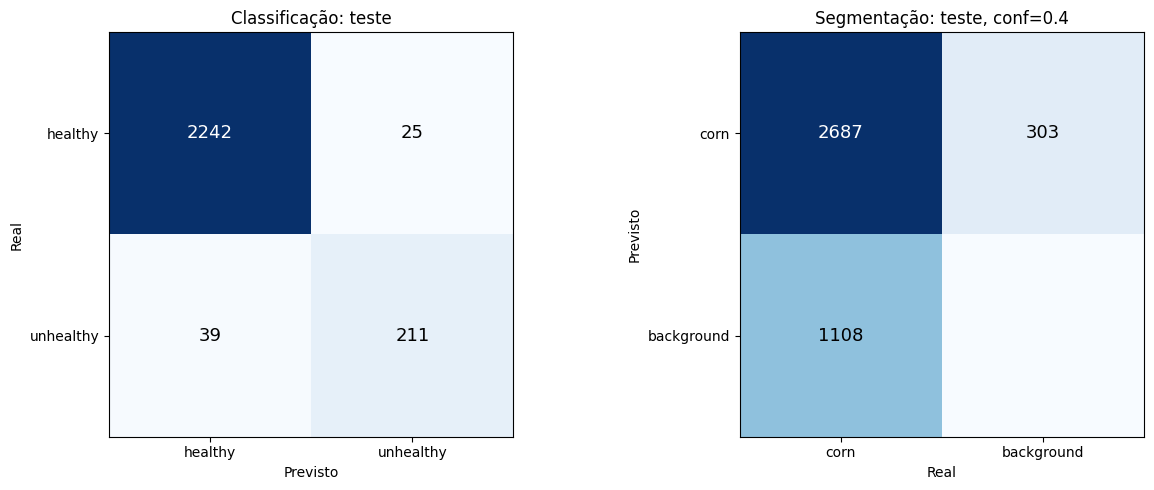

In [8]:
# Matrizes de confusão no conjunto de teste (valores dos relatórios de treino). Mesma ordem da seção 2: classificação e depois segmentação.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Classificação: linhas = real, colunas = previsto
cm_cls = np.array([[2242, 25], [39, 211]])
axes[0].imshow(cm_cls, cmap="Blues")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["healthy", "unhealthy"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["healthy", "unhealthy"])
axes[0].set_xlabel("Previsto"); axes[0].set_ylabel("Real")
axes[0].set_title("Classificação: teste")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm_cls[i, j]), ha="center", va="center",
                     color="white" if cm_cls[i, j] > 1000 else "black", fontsize=13)

# Segmentação (conf=0.4): linhas = previsto, colunas = real
cm_seg = np.array([[2687, 303], [1108, 0]])
axes[1].imshow(cm_seg, cmap="Blues")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["corn", "background"])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["corn", "background"])
axes[1].set_xlabel("Real"); axes[1].set_ylabel("Previsto")
axes[1].set_title("Segmentação: teste, conf=0.4")
for i in range(2):
    for j in range(2):
        if (i, j) != (1, 1):
            axes[1].text(j, i, str(cm_seg[i, j]), ha="center", va="center",
                         color="white" if cm_seg[i, j] > 1500 else "black", fontsize=13)

plt.tight_layout()
plt.show()


## 4. Treinamento completo (opcional)

As células abaixo **treinam os dois modelos do zero**, com os mesmos hiperparâmetros do TCC. Elas ficam desligadas por padrão (`RETREINAR = False`) porque:

- precisam de **GPU** (Ambiente de execução > Alterar tipo de ambiente > T4);
- levam muito tempo com as 100 épocas originais (cerca de 1h30 a 2h por modelo). Para uma demonstração rápida, use `EPOCAS = 3`;
- baixam o dataset do Release `dataset-v1` do repositório: cerca de 0,7 GB o de classificação e 4,6 GB o de segmentação.

Para ligar, mude `RETREINAR` para `True`. O treino novo é salvo em `runs/` e **não** sobrescreve os pesos de `weights/`.

In [9]:
RETREINAR = False          # mude para True para treinar
EPOCAS = 100               # use 3 para uma demonstração rápida (os resultados NÃO serão equivalentes)

import zipfile, urllib.request
TAG_DATASET = "dataset-v1"
BASE_RELEASE = f"https://github.com/blick-ai/blick-treino/releases/download/{TAG_DATASET}"
ZIPS_CLS = ["blick-classification.zip"]       # Folder Structure: train/valid/test, cada uma com healthy/ e unhealthy/
ZIPS_SEG = ["blick-segmentation-train-1.zip",  # COCO Segmentation. O train foi dividido em duas partes
            "blick-segmentation-train-2.zip",  # (as duas caem na mesma pasta train/; o .json está na parte 1)
            "blick-segmentation-valid.zip",
            "blick-segmentation-test.zip"]

def baixar_e_extrair(nomes, destino):
    os.makedirs(destino, exist_ok=True)
    for nome in nomes:
        print("Baixando", nome, "...")
        urllib.request.urlretrieve(f"{BASE_RELEASE}/{nome}", nome)
        with zipfile.ZipFile(nome) as z:
            z.extractall(destino)
        os.remove(nome)

def acha_raiz(pasta):
    # pasta que contém train/ e valid/ (ou val/), mesmo que o zip tenha uma pasta de embrulho
    for raiz, dirs, _ in os.walk(pasta):
        if "train" in dirs and ({"valid", "val", "validation"} & set(dirs)):
            return raiz
    return None

In [10]:
# --- Treino do CLASSIFICADOR (yolo26n-cls): 224x224, lote 64, paciência 20 ---
if RETREINAR:
    if not os.path.isdir("dataset/classificacao"):      # reaproveita o download da seção 2.2, se já existir
        baixar_e_extrair(ZIPS_CLS, "dataset/classificacao")
    dados_cls = acha_raiz("dataset/classificacao")

    novo_cls = YOLO("yolo26n-cls.pt")
    novo_cls.train(
        data=dados_cls,
        epochs=EPOCAS,
        imgsz=224,
        batch=64,
        patience=20,
        name="milho_healthy_unhealthy_retreino",
        device=0,
        cache="ram",
    )
    print("Pesos salvos em runs/classify/milho_healthy_unhealthy_retreino/weights/best.pt")
else:
    print("Treino do classificador desligado (RETREINAR=False).")

Treino do classificador desligado (RETREINAR=False).


In [11]:
# --- Treino do SEGMENTADOR (yolo26n-seg): 640x640, lote 16, paciência 20 ---
if RETREINAR:
    !pip install -q pycocotools
    import glob, shutil, json as json_lib
    from pycocotools import mask as mask_utils

    if not os.path.isdir("coco_raw"):
        baixar_e_extrair(ZIPS_SEG, "coco_raw")   # as duas partes do train juntam na mesma pasta train/

    def json_do_split(padrao):
        achados = [j for j in glob.glob("coco_raw/**/*.json", recursive=True)
                   if padrao in os.path.basename(os.path.dirname(j)).lower()]
        assert len(achados) == 1, f"Esperava 1 json para '{padrao}', achei {achados}"
        return achados[0]

    splits_json = {"train": json_do_split("train"), "valid": json_do_split("val"), "test": json_do_split("test")}

    def poligonos_da_anotacao(seg, w, h):
        polis = []
        if isinstance(seg, dict):  # máscara RLE -> contorno
            rle = mask_utils.frPyObjects(seg, h, w) if isinstance(seg.get("counts"), list) else seg
            m = mask_utils.decode(rle)
            m = m[:, :, 0] if m.ndim == 3 else m
            cont, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            polis += [c.reshape(-1, 2).astype(float) for c in cont if len(c) >= 3]
        elif isinstance(seg, list):
            polis += [np.array(p, dtype=float).reshape(-1, 2) for p in seg if isinstance(p, list) and len(p) >= 6]
        return polis

    categorias = sorted(json_lib.load(open(splits_json["train"]))["categories"], key=lambda c: c["id"])
    cat_idx = {c["id"]: i for i, c in enumerate(categorias)}
    nomes = [c["name"] for c in categorias]

    for split, jpath in splits_json.items():
        d = json_lib.load(open(jpath))
        pasta = Path(jpath).parent
        out_i, out_l = Path("dataset_seg/images")/split, Path("dataset_seg/labels")/split
        out_i.mkdir(parents=True, exist_ok=True); out_l.mkdir(parents=True, exist_ok=True)
        anns = {}
        for a in d["annotations"]:
            anns.setdefault(a["image_id"], []).append(a)
        for img in d["images"]:
            if not (pasta / img["file_name"]).exists():
                continue
            shutil.copy(pasta / img["file_name"], out_i / img["file_name"])
            linhas = []
            for a in anns.get(img["id"], []):
                for pts in poligonos_da_anotacao(a.get("segmentation"), img["width"], img["height"]):
                    coords = [f"{v:.6f}" for x, y in pts for v in (x / img["width"], y / img["height"])]
                    linhas.append(str(cat_idx[a["category_id"]]) + " " + " ".join(coords))
            if linhas:   # imagens sem anotação (sem milho) ficam sem .txt
                (out_l / (Path(img["file_name"]).stem + ".txt")).write_text("\n".join(linhas))

    yaml = "path: " + str(Path("dataset_seg").resolve()) + "\ntrain: images/train\nval: images/valid\ntest: images/test\nnames:\n"
    yaml += "".join(f"  {i}: {n}\n" for i, n in enumerate(nomes))
    Path("dataset_seg/data.yaml").write_text(yaml)

    novo_seg = YOLO("yolo26n-seg.pt")
    novo_seg.train(
        data="dataset_seg/data.yaml",
        epochs=EPOCAS,
        imgsz=640,
        batch=16,
        patience=20,
        name="milho_corn_seg_retreino",
        device=0,
    )
    print("Pesos salvos em runs/segment/milho_corn_seg_retreino/weights/best.pt")
else:
    print("Treino do segmentador desligado (RETREINAR=False).")

Treino do segmentador desligado (RETREINAR=False).


## 5. Inferência: carrega os dois modelos treinados

In [12]:
model_seg = YOLO("weights/segmentacao_best.pt")
model_cls = YOLO("weights/classificacao_best.pt")
print("Classes da segmentação:", model_seg.names)
print("Classes da classificação:", model_cls.names)

# O modelo de segmentação tem duas classes: a 0 ('Blick-corn-analyzer') não tem anotações,
# e a 1 ('corn') é o milho. A busca precisa ser por nome EXATO, não por substring.
IDX_CLASSE_CORN = next(i for i, n in model_seg.names.items() if n.lower() in ("corn", "milho"))
print("Índice da classe corn:", IDX_CLASSE_CORN)

# Cada .pt é uma rede neural treinada. info() lista as camadas e o número de parâmetros (pesos).
print("\n--- Rede 1: segmentador ---")
model_seg.info()
print("\n--- Rede 2: classificador ---")
model_cls.info()

Classes da segmentação: {0: 'Blick-corn-analyze', 1: 'corn'}
Classes da classificação: {0: 'healthy', 1: 'unhealthy'}
Índice da classe corn: 1

--- Rede 1: segmentador ---
YOLO26n-seg summary: 309 layers, 3,053,510 parameters, 0 gradients, 10.3 GFLOPs

--- Rede 2: classificador ---
YOLO26n-cls summary: 86 layers, 1,533,666 parameters, 0 gradients, 3.3 GFLOPs


(86, 1533666, 0, 3.31275008)

## 6. Fotos de exemplo

O notebook usa até 4 fotos da pasta `images_test/` do repositório (ou `exemplos/entrada/`, se existir). Se não houver fotos lá, aparece um botão para você enviar as suas.

In [13]:
from pathlib import Path
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MAX_IMAGENS = 4

pasta = next((Path(d) for d in ("images_test", "exemplos/entrada") if Path(d).exists()), Path("images_test"))
imagens = sorted(p for p in pasta.glob("*") if p.suffix.lower() in EXT)[:MAX_IMAGENS] if pasta.exists() else []

if not imagens:
    print(f"Nenhuma foto em {pasta}. Envie até 4 fotos de milho:")
    from google.colab import files
    pasta.mkdir(parents=True, exist_ok=True)
    for nome, conteudo in files.upload().items():
        (pasta / nome).write_bytes(conteudo)
    imagens = sorted(p for p in pasta.glob("*") if p.suffix.lower() in EXT)[:MAX_IMAGENS]

print(f"{len(imagens)} imagem(ns) em {pasta}:")
for p in imagens:
    print(" ", p.name)

4 imagem(ns) em images_test:
  20260911223136-24a1ffef.jpg
  20260911223137-4aa9771b.jpg
  20260911223138-dff00826.jpg
  20260911223140-58a059b3.jpg


## 7. Funções do pipeline

`CONF_SEG` é o limiar de confiança do segmentador. As métricas do artigo foram medidas com 0,40; a API opera com 0,25. Para fotos escuras ou com plantas distantes, vale testar 0,25.

In [14]:
import cv2
import numpy as np

CONF_SEG = 0.40
PADDING = 15


def isolar_instancias(imagem, poligonos, padding=PADDING):
    altura, largura = imagem.shape[:2]
    saida = []
    for poligono in poligonos:
        pontos = np.round(poligono).astype(np.int32)
        if len(pontos) < 3:
            continue
        mascara = np.zeros((altura, largura), dtype=np.uint8)
        cv2.fillPoly(mascara, [pontos], 255)
        isolado = cv2.bitwise_and(imagem, imagem, mask=mascara)
        x, y, w, h = cv2.boundingRect(mascara)
        x1, y1 = max(0, x - padding), max(0, y - padding)
        x2, y2 = min(largura, x + w + padding), min(altura, y + h + padding)
        crop = isolado[y1:y2, x1:x2]
        if crop.size == 0:
            continue
        saida.append({"crop": crop, "bbox": (x1, y1, x2, y2), "poligono": pontos})
    return saida


IDX_UNHEALTHY = next(i for i, n in model_cls.names.items() if n == "unhealthy")


def quadrado(img):
    # completa o recorte com preto até ficar quadrado. Hipótese (a confirmar): sem isso, o pré-processamento
    # do classificador (redimensiona o lado curto e corta o centro) perderia o topo e a base de recortes altos e estreitos.
    h, w = img.shape[:2]
    s = max(h, w)
    out = np.zeros((s, s, 3), dtype=img.dtype)
    y, x = (s - h) // 2, (s - w) // 2
    out[y:y + h, x:x + w] = img
    return out


def processar_imagem(caminho, conf_seg=CONF_SEG, usar_quadrado=True, limiar_unhealthy=0.30):
    # usar_quadrado=True: o recorte é completado com preto até ficar quadrado antes de ir ao classificador.
    # limiar_unhealthy=0.30: uma planta é unhealthy se p(unhealthy) >= 0,30. O treino usou 0,50 (top-1).
    # O corte baixo é uma escolha de projeto: perder um adesivo custa mais do que um falso alarme.
    imagem = cv2.imread(str(caminho))
    if imagem is None:
        raise IOError(f"Não consegui abrir {caminho}")

    res = model_seg.predict(imagem, conf=conf_seg, device=DEVICE, verbose=False)[0]
    polis = []
    if res.masks is not None:
        classes = res.boxes.cls.cpu().numpy().astype(int)
        confs = res.boxes.conf.cpu().numpy()
        for poli, c, conf in zip(res.masks.xy, classes, confs):
            if c == IDX_CLASSE_CORN:
                polis.append((poli, float(conf)))

    instancias = []
    if polis:
        isolados = isolar_instancias(imagem, [p for p, _ in polis])
        for iso, (_, conf_det) in zip(isolados, polis):
            entrada = quadrado(iso["crop"]) if usar_quadrado else iso["crop"]
            r = model_cls.predict(entrada, device=DEVICE, verbose=False)[0]
            p_unh = float(r.probs.data[IDX_UNHEALTHY])        # probabilidade de unhealthy (0 a 1)
            unh = p_unh >= limiar_unhealthy
            instancias.append({
                "poligono": iso["poligono"], "bbox": iso["bbox"],
                "conf_deteccao": conf_det,
                "crop": iso["crop"],
                "p_unhealthy": p_unh,
                "classe_saude": "unhealthy" if unh else "healthy",
                "conf_saude": p_unh if unh else 1 - p_unh,
            })

    if not instancias:
        veredito = "sem milho detectado"
    elif any(i["classe_saude"] == "unhealthy" for i in instancias):
        veredito = "unhealthy"
    else:
        veredito = "healthy"
    return {"caminho": str(caminho), "imagem": imagem, "instancias": instancias, "veredito": veredito}

## 8. Roda o pipeline

In [15]:
resultados = [processar_imagem(p) for p in imagens]

for r in resultados:
    nh = sum(i["classe_saude"] == "healthy" for i in r["instancias"])
    nu = sum(i["classe_saude"] == "unhealthy" for i in r["instancias"])
    print(f"{Path(r['caminho']).name:40s} -> {len(r['instancias'])} planta(s) ({nh} healthy, {nu} unhealthy) | veredito: {r['veredito'].upper()}")

20260911223136-24a1ffef.jpg              -> 3 planta(s) (2 healthy, 1 unhealthy) | veredito: UNHEALTHY
20260911223137-4aa9771b.jpg              -> 3 planta(s) (2 healthy, 1 unhealthy) | veredito: UNHEALTHY
20260911223138-dff00826.jpg              -> 3 planta(s) (2 healthy, 1 unhealthy) | veredito: UNHEALTHY
20260911223140-58a059b3.jpg              -> 4 planta(s) (2 healthy, 2 unhealthy) | veredito: UNHEALTHY


### 8.1 Diagnóstico: probabilidade de `unhealthy` por planta

A rede devolve uma **probabilidade**, e o veredito é só um corte nela. O treino usou 0,50 (top-1); o pipeline desta seção usa 0,30 por padrão. Esta célula mostra, para cada foto, a probabilidade de cada planta e compara três configurações: a original, o recorte completado para quadrado, e o quadrado com corte mais baixo (0,30). Serve para ver **por que** uma planta com adesivo às vezes sai `healthy`: costuma ser uma probabilidade perto do corte, não um erro grosseiro.

In [16]:
CONFIGS = [("original (corte 0,50)", False, 0.50),
           ("quadrado (corte 0,50)", True, 0.50),
           ("quadrado (corte 0,30)", True, 0.30)]

for p in imagens:
    print(p.name)
    for nome_cfg, quad, lim in CONFIGS:
        r = processar_imagem(p, usar_quadrado=quad, limiar_unhealthy=lim)
        probs = " ".join(f"{i['p_unhealthy']:.0%}" for i in r["instancias"]) or "-"
        print(f"   {nome_cfg:24s} veredito: {r['veredito'].upper():22s} p(unhealthy) por planta: {probs}")

20260911223136-24a1ffef.jpg
   original (corte 0,50)    veredito: HEALTHY                p(unhealthy) por planta: 0% 39% 0%
   quadrado (corte 0,50)    veredito: UNHEALTHY              p(unhealthy) por planta: 0% 67% 0%
   quadrado (corte 0,30)    veredito: UNHEALTHY              p(unhealthy) por planta: 0% 67% 0%
20260911223137-4aa9771b.jpg
   original (corte 0,50)    veredito: HEALTHY                p(unhealthy) por planta: 0% 39% 0%
   quadrado (corte 0,50)    veredito: UNHEALTHY              p(unhealthy) por planta: 0% 67% 0%
   quadrado (corte 0,30)    veredito: UNHEALTHY              p(unhealthy) por planta: 0% 67% 0%
20260911223138-dff00826.jpg
   original (corte 0,50)    veredito: HEALTHY                p(unhealthy) por planta: 0% 29% 0%
   quadrado (corte 0,50)    veredito: UNHEALTHY              p(unhealthy) por planta: 1% 68% 0%
   quadrado (corte 0,30)    veredito: UNHEALTHY              p(unhealthy) por planta: 1% 68% 0%
20260911223140-58a059b3.jpg
   original (corte 0,50)

## 9. Visualização

Verde = `healthy`, vermelho = `unhealthy`. O título mostra o veredito da imagem.

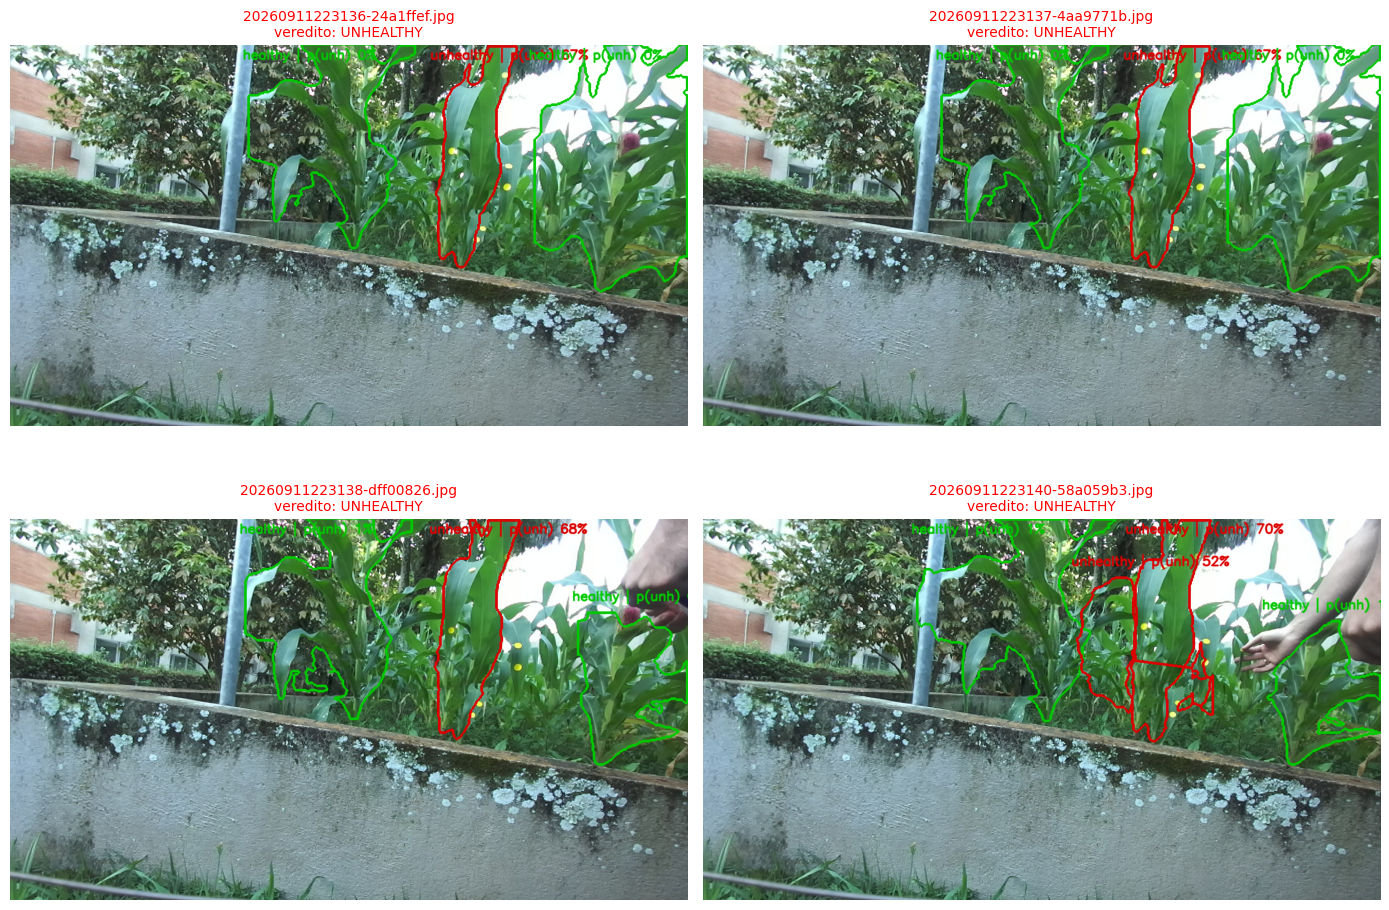

In [17]:
import matplotlib.pyplot as plt

COR = {"healthy": (0, 200, 0), "unhealthy": (220, 0, 0)}


def desenhar(r):
    img = cv2.cvtColor(r["imagem"], cv2.COLOR_BGR2RGB).copy()
    for i in r["instancias"]:
        cor = COR[i["classe_saude"]]
        cv2.polylines(img, [i["poligono"]], True, cor, 3)
        x1, y1, _, _ = i["bbox"]
        ty = y1 - 8 if y1 > 30 else y1 + 28          # se a caixa encosta no topo, escreve dentro dela
        cv2.putText(img, f"{i['classe_saude']} | p(unh) {i['p_unhealthy']:.0%}", (x1 + 4, ty),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, cor, 2, cv2.LINE_AA)
    return img


n_col = min(2, max(1, len(resultados)))
n_lin = (len(resultados) + n_col - 1) // n_col
fig, axes = plt.subplots(n_lin, n_col, figsize=(7 * n_col, 5 * n_lin))
axes = np.array(axes).reshape(-1)
for ax, r in zip(axes, resultados):
    ax.imshow(desenhar(r))
    cor_t = {"unhealthy": "red", "healthy": "green"}.get(r["veredito"], "gray")
    ax.set_title(f"{Path(r['caminho']).name}\nveredito: {r['veredito'].upper()}", color=cor_t, fontsize=10)
    ax.axis("off")
for ax in axes[len(resultados):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Limitações

- O rótulo `unhealthy` corresponde à presença de um adesivo simulando sintoma; o reconhecimento de doenças reais não foi testado.
- A divisão treino/validação/teste do classificador foi estratificada por classe e feita por recorte, não por foto de origem, então as métricas do classificador são otimistas.
- O segmentador omite cerca de um terço das plantas (recall de máscara 0,67), e isso limita o que chega ao classificador.